# Exploratory Data Analysis (EDA) Project
## Dataset: 120 Years of Olympic History — Athletes and Results

**Objective:** Perform a complete, well-documented EDA following the project guidelines:
1. Understand the Dataset
2. Data Preprocessing (cleaning, missing values, outliers, inconsistencies)
3. Exploratory Data Analysis (visualizations, patterns, relationships)
4. Feature Engineering & Extraction
5. Encoding (Label Encoding & One-Hot Encoding) — converting all object dtypes to numeric
6. Feature Scaling
7. Insights and Interpretation


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)


## 2. Understand the Dataset
Load the data and inspect its structure, shape, data types, and basic context.

In [2]:
df = pd.read_csv("athlete_data.csv")
print('Shape of dataset:', df.shape)
df.head()


Shape of dataset: (271116, 15)


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [4]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,271116.0,NaN,NaN,NaN,68248.954396,39022.286345,1.0,34643.0,68205.0,102097.25,135571.0
Name,271116,134732,Robert Tait McKenzie,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,271116,2,M,196594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,261642.0,NaN,NaN,NaN,25.556898,6.393561,10.0,21.0,24.0,28.0,97.0
Height,210945.0,NaN,NaN,NaN,175.33897,10.518462,127.0,168.0,175.0,183.0,226.0
Weight,208241.0,NaN,NaN,NaN,70.702393,14.34802,25.0,60.0,70.0,79.0,214.0
Team,271116,1184,United States,17847,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NOC,271116,230,USA,18853,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Games,271116,51,2000 Summer,13821,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,271116.0,NaN,NaN,NaN,1978.37848,29.877632,1896.0,1960.0,1988.0,2002.0,2016.0


**Context:** This dataset contains information on athletes who competed in the Olympic Games from 1896 to 2016 — including their physical attributes (Age, Height, Weight), the country/team they represented, the event/sport they competed in, and the medal (if any) they won.

**Columns:**
- `ID`, `Name` — identifiers
- `Sex` — M/F
- `Age`, `Height`, `Weight` — numeric attributes
- `Team`, `NOC` — country/team representation
- `Games`, `Year`, `Season`, `City` — event details
- `Sport`, `Event` — competition details
- `Medal` — Gold / Silver / Bronze / NA (no medal)


In [5]:
print('Number of duplicate rows:', df.duplicated().sum())
print('\nUnique value counts per column:')
df.nunique()


Number of duplicate rows: 1385

Unique value counts per column:


ID        135571
Name      134732
Sex            2
Age           74
Height        95
Weight       220
Team        1184
NOC          230
Games         51
Year          35
Season         2
City          42
Sport         66
Event        765
Medal          3
dtype: int64

## 2.1 Value Counts for All Categorical Columns

In [6]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print('Categorical columns:', categorical_cols)

for col in categorical_cols:
    print(f'\n--- Value counts for {col} (top 15) ---')
    print(df[col].value_counts().head(15))


Categorical columns: ['Name', 'Sex', 'Team', 'NOC', 'Games', 'Season', 'City', 'Sport', 'Event', 'Medal']

--- Value counts for Name (top 15) ---
Name
Robert Tait McKenzie                58
Heikki Ilmari Savolainen            39
Joseph "Josy" Stoffel               38
Ioannis Theofilakis                 36
Takashi Ono                         33
Andreas Wecker                      32
Alexandros Theofilakis              32
Alfrd (Arnold-) Hajs (Guttmann-)    32
Jean Lucien Nicolas Jacoby          32
Michel Mathiot                      31
Alfred James Munnings               31
Johann "Hans" Sauter                31
Alfred August "Al" Jochim           31
Karl Tore William Thoresson         30
Yordan Yovchev Yovchev              30
Name: count, dtype: int64

--- Value counts for Sex (top 15) ---
Sex
M    196594
F     74522
Name: count, dtype: int64

--- Value counts for Team (top 15) ---
Team
United States    17847
France           11988
Great Britain    11404
Italy            10260
Germany 

In [7]:
print('Sex value counts:\n', df['Sex'].value_counts(), '\n')
print('Season value counts:\n', df['Season'].value_counts(), '\n')
print('Medal value counts (including NaN):\n', df['Medal'].value_counts(dropna=False), '\n')
print('Top 15 Sports:\n', df['Sport'].value_counts().head(15), '\n')
print('Top 15 NOC (countries):\n', df['NOC'].value_counts().head(15), '\n')
print('Top 15 Teams:\n', df['Team'].value_counts().head(15), '\n')
print('City value counts:\n', df['City'].value_counts(), '\n')


Sex value counts:
 Sex
M    196594
F     74522
Name: count, dtype: int64 

Season value counts:
 Season
Summer    222552
Winter     48564
Name: count, dtype: int64 

Medal value counts (including NaN):
 Medal
NaN       231333
Gold       13372
Bronze     13295
Silver     13116
Name: count, dtype: int64 

Top 15 Sports:
 Sport
Athletics               38624
Gymnastics              26707
Swimming                23195
Shooting                11448
Cycling                 10859
Fencing                 10735
Rowing                  10595
Cross Country Skiing     9133
Alpine Skiing            8829
Wrestling                7154
Football                 6745
Sailing                  6586
Equestrianism            6344
Canoeing                 6171
Boxing                   6047
Name: count, dtype: int64 

Top 15 NOC (countries):
 NOC
USA    18853
FRA    12758
GBR    12256
ITA    10715
GER     9830
CAN     9733
JPN     8444
SWE     8339
AUS     7638
HUN     6607
POL     6207
SUI     6150
NED     58

## 3. Data Preprocessing
### 3.1 Missing Values

In [8]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)


,Missing Count,Missing %
Medal,231333,85.326207
Weight,62875,23.191180
Height,60171,22.193821
Age,9474,3.494445


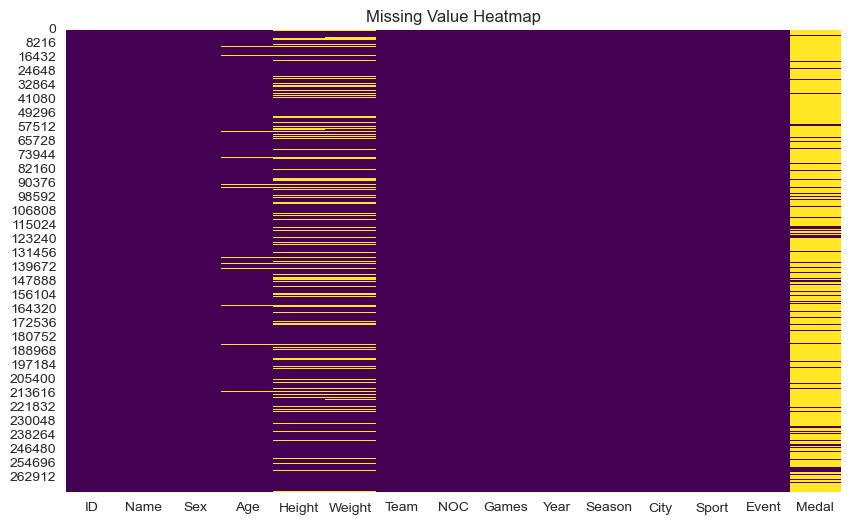

In [9]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Value Heatmap')
plt.show()


**Observations:**
- `Medal` has a large number of missing values — this is *expected* since most athletes do not win a medal. We will treat this as a category `'No Medal'` rather than drop or impute it.
- `Age`, `Height`, `Weight` have genuine missing values that need imputation.
- `Name`, `Sex`, `Team`, `NOC`, `Games`, `Year`, `Season`, `City`, `Sport`, `Event` have no missing values.


In [10]:
# Fill Medal NA with 'No Medal' since it's a valid category, not a true missing value
df['Medal'] = df['Medal'].fillna('No Medal')
df['Medal'].value_counts()


Medal
No Medal    231333
Gold         13372
Bronze       13295
Silver       13116
Name: count, dtype: int64

In [11]:
# Impute Age, Height, Weight with median grouped by Sex and Sport for more accurate imputation
for col in ['Age', 'Height', 'Weight']:
    df[col] = df.groupby(['Sex', 'Sport'])[col].transform(lambda x: x.fillna(x.median()))

# Any remaining NaNs (rare combos with no data at all) filled with overall median
for col in ['Age', 'Height', 'Weight']:
    df[col] = df[col].fillna(df[col].median())

print('Missing values after imputation:')
print(df[['Age','Height','Weight']].isnull().sum())


Missing values after imputation:
Age       0
Height    0
Weight    0
dtype: int64


### 3.2 Checking and Handling Outliers

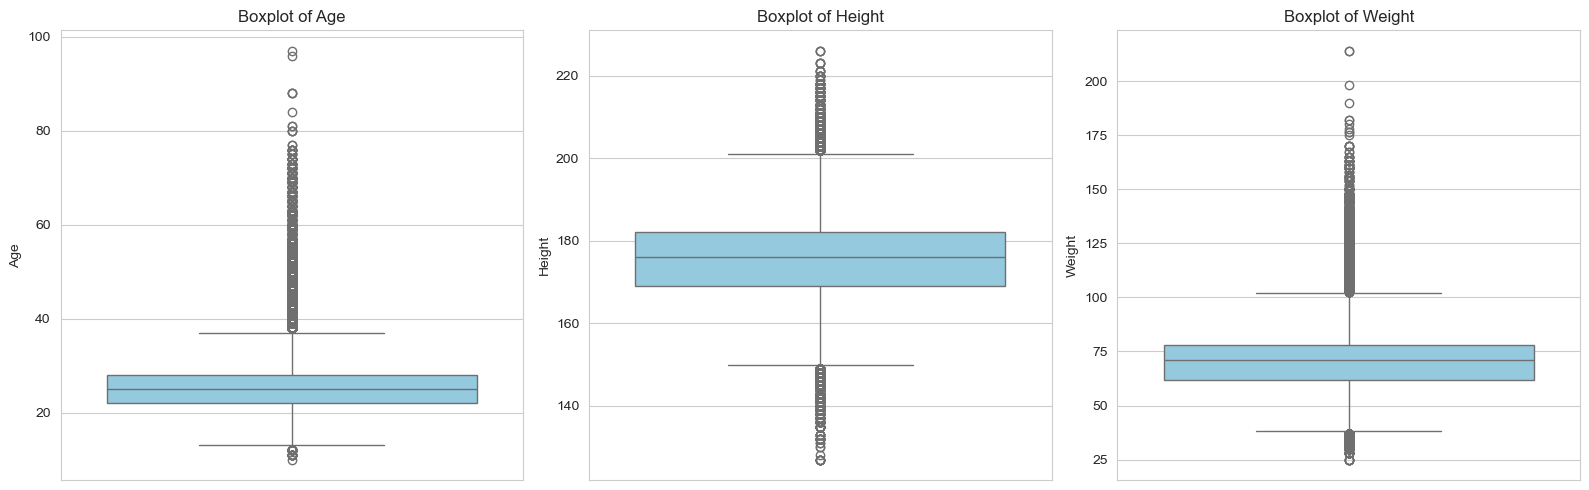

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))
for ax, col in zip(axes, ['Age', 'Height', 'Weight']):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()


In [13]:
# Identify outliers using IQR method
def iqr_outlier_bounds(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5*IQR, Q3 + 1.5*IQR

for col in ['Age', 'Height', 'Weight']:
    lower, upper = iqr_outlier_bounds(df[col])
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: lower={lower:.1f}, upper={upper:.1f}, outliers={n_outliers}')


Age: lower=13.0, upper=37.0, outliers=12491
Height: lower=149.5, upper=201.5, outliers=3024
Weight: lower=38.0, upper=102.0, outliers=5357


**Decision:** Olympic athletes legitimately span a wide range of ages, heights, and weights (e.g., gymnasts vs. weightlifters vs. shooters), so most "outliers" are real, valid data points rather than errors. We will **cap extreme values** (clip) rather than remove rows, to retain data while limiting the influence of truly extreme entries.

In [14]:
for col in ['Age', 'Height', 'Weight']:
    lower, upper = iqr_outlier_bounds(df[col])
    df[col] = df[col].clip(lower=lower, upper=upper)

print('Outliers capped. New ranges:')
df[['Age','Height','Weight']].describe()


Outliers capped. New ranges:


,Age,Height,Weight
count,271116.000000,271116.000000,271116.000000
mean,25.244342,175.556293,70.833075
std,5.234260,9.685140,12.454287
min,13.000000,149.500000,38.000000
25%,22.000000,169.000000,62.000000
50%,25.000000,176.000000,71.000000
75%,28.000000,182.000000,78.000000
max,37.000000,201.500000,102.000000


### 3.3 Checking for Inconsistencies

In [15]:
# Check for inconsistent text casing / extra spaces in categorical columns
for col in ['Sex', 'Season', 'Medal']:
    print(col, '->', df[col].unique())


Sex -> ['M' 'F']
Season -> ['Summer' 'Winter']
Medal -> ['No Medal' 'Gold' 'Bronze' 'Silver']


In [16]:
# Standardize text columns (strip whitespace)
for col in categorical_cols:
    df[col] = df[col].str.strip()

print('Inconsistencies cleaned (whitespace stripped from all text columns).')


Inconsistencies cleaned (whitespace stripped from all text columns).


## 4. Exploratory Data Analysis & Visualization

### 4.1 Univariate Analysis

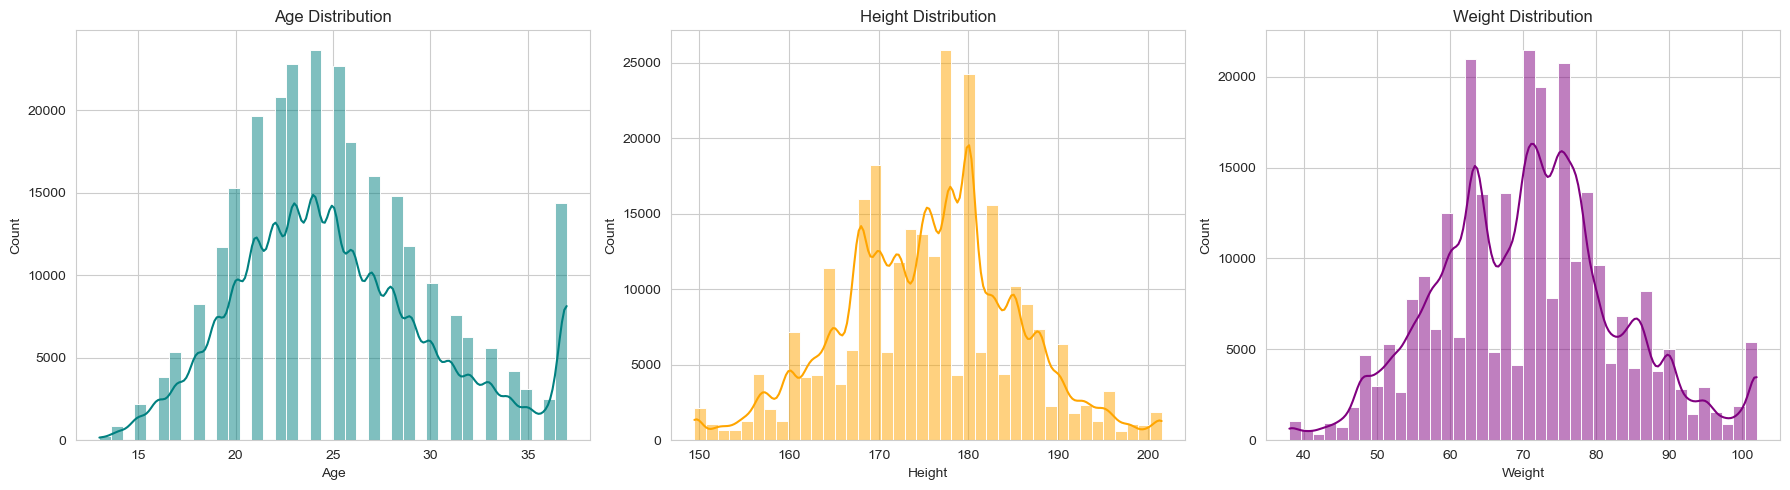

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
sns.histplot(df['Age'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Age Distribution')
sns.histplot(df['Height'], bins=40, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Height Distribution')
sns.histplot(df['Weight'], bins=40, kde=True, ax=axes[2], color='purple')
axes[2].set_title('Weight Distribution')
plt.tight_layout()
plt.show()


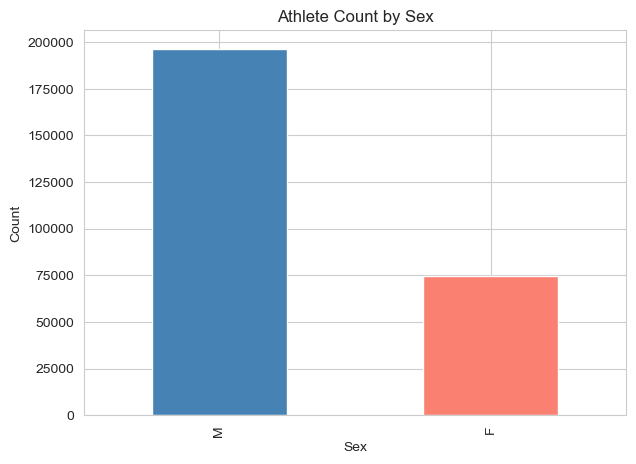

In [18]:
plt.figure(figsize=(7,5))
df['Sex'].value_counts().plot(kind='bar', color=['steelblue','salmon'])
plt.title('Athlete Count by Sex')
plt.ylabel('Count')
plt.show()


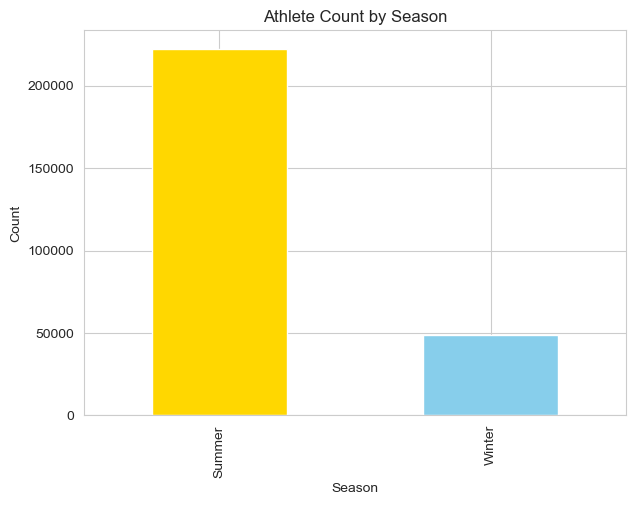

In [19]:
plt.figure(figsize=(7,5))
df['Season'].value_counts().plot(kind='bar', color=['gold','skyblue'])
plt.title('Athlete Count by Season')
plt.ylabel('Count')
plt.show()


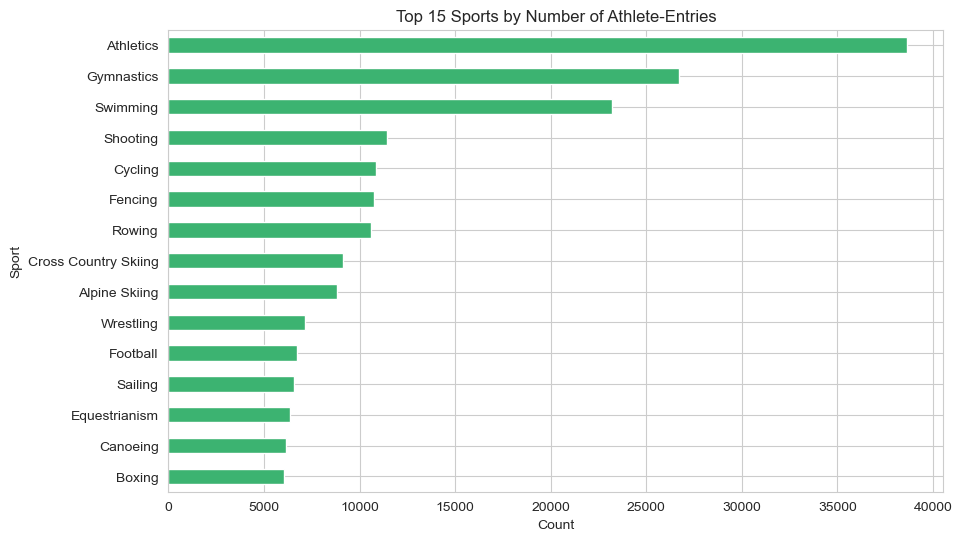

In [20]:
plt.figure(figsize=(10,6))
df['Sport'].value_counts().head(15).plot(kind='barh', color='mediumseagreen')
plt.title('Top 15 Sports by Number of Athlete-Entries')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.show()


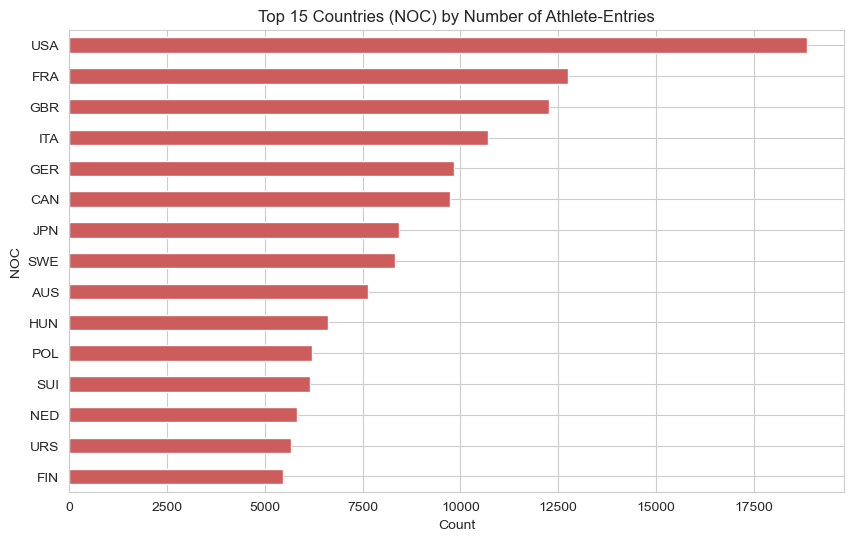

In [21]:
plt.figure(figsize=(10,6))
df['NOC'].value_counts().head(15).plot(kind='barh', color='indianred')
plt.title('Top 15 Countries (NOC) by Number of Athlete-Entries')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.show()


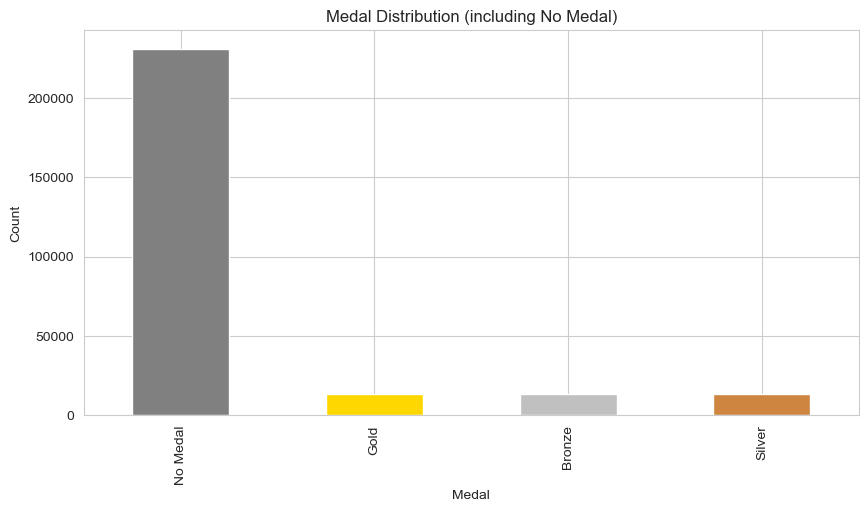

In [22]:
plt.figure(figsize=(10,5))
df['Medal'].value_counts().plot(kind='bar', color=['gray','gold','silver','peru'])
plt.title('Medal Distribution (including No Medal)')
plt.ylabel('Count')
plt.show()


### 4.2 Trend Over Time

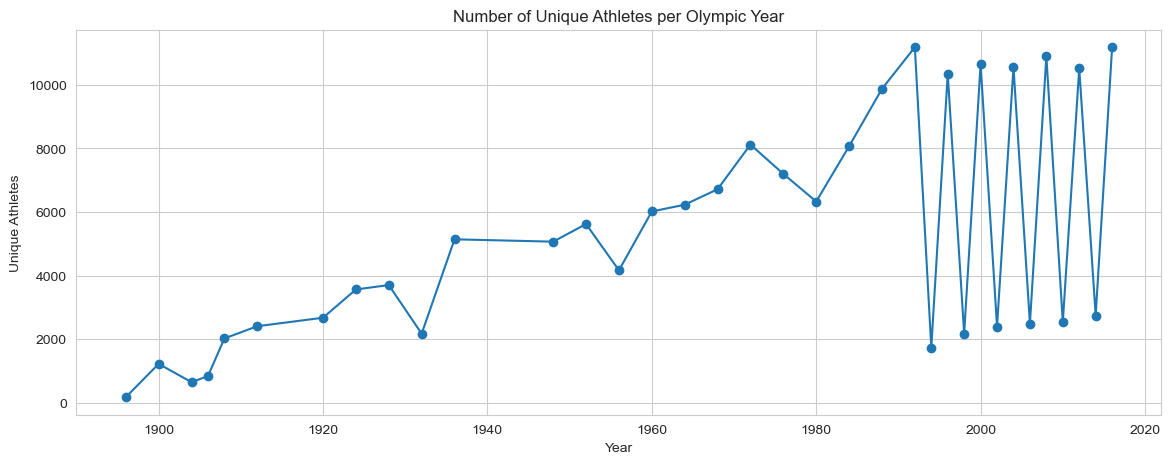

In [23]:
yearly_counts = df.groupby('Year')['ID'].nunique()
plt.figure(figsize=(14,5))
yearly_counts.plot(marker='o')
plt.title('Number of Unique Athletes per Olympic Year')
plt.xlabel('Year')
plt.ylabel('Unique Athletes')
plt.show()


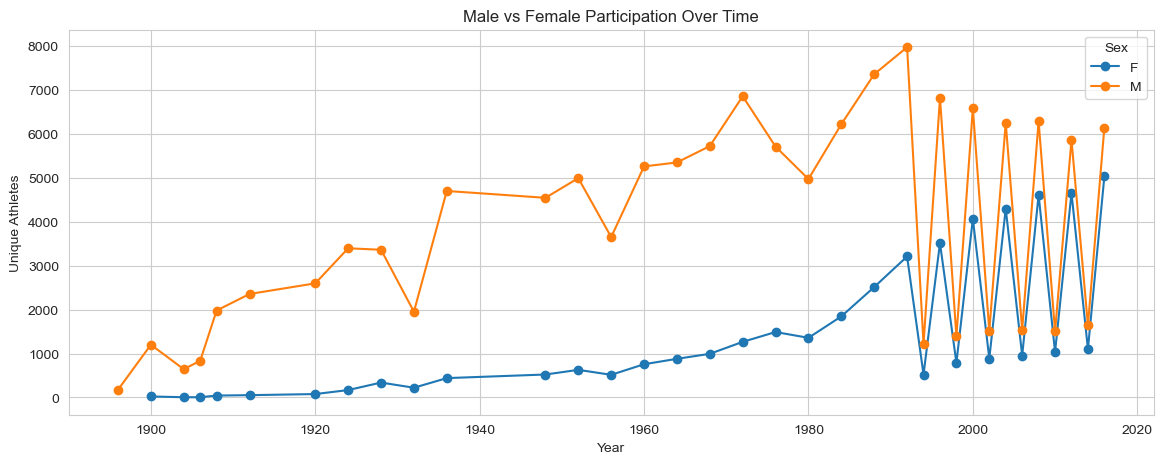

In [24]:
gender_year = df.groupby(['Year','Sex'])['ID'].nunique().unstack()
plt.figure(figsize=(14,5))
gender_year.plot(marker='o', ax=plt.gca())
plt.title('Male vs Female Participation Over Time')
plt.xlabel('Year')
plt.ylabel('Unique Athletes')
plt.show()


### 4.3 Bivariate / Multivariate Analysis

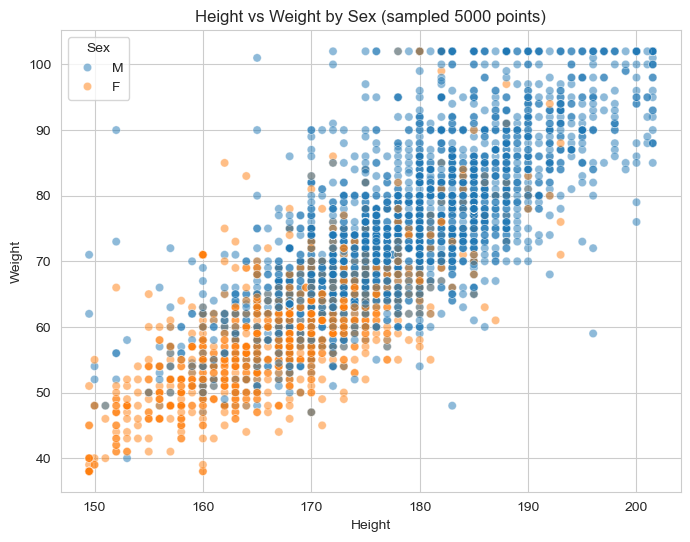

In [25]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df.sample(5000, random_state=42), x='Height', y='Weight', hue='Sex', alpha=0.5)
plt.title('Height vs Weight by Sex (sampled 5000 points)')
plt.show()


C:\Users\ritik\AppData\Local\Temp\ipykernel_20656\4037022618.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Sex', y='Age', palette='Set2')


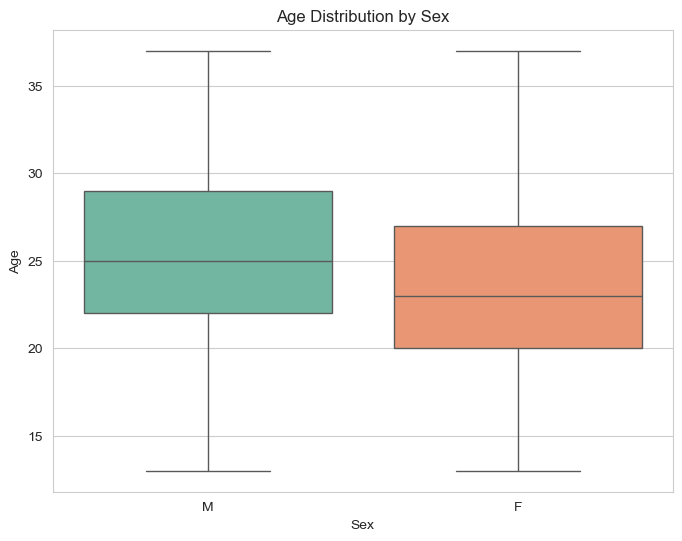

In [26]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='Sex', y='Age', palette='Set2')
plt.title('Age Distribution by Sex')
plt.show()


C:\Users\ritik\AppData\Local\Temp\ipykernel_20656\1716158989.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=medal_winners, x='Medal', y='Age', order=['Gold','Silver','Bronze'], palette='Set3')


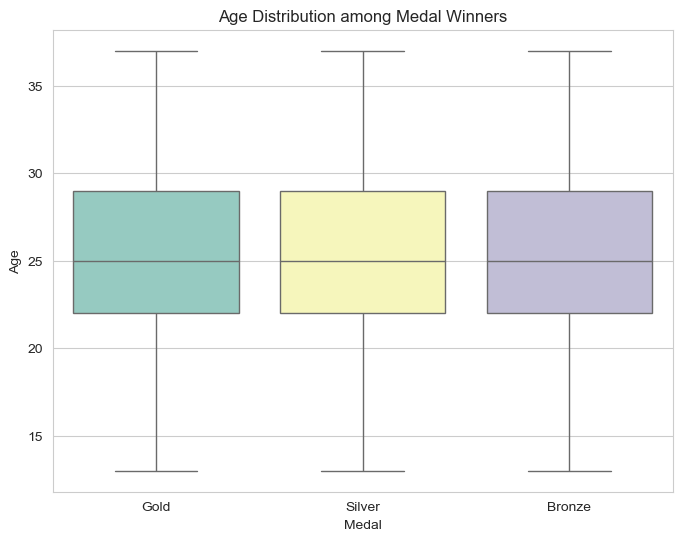

In [27]:
medal_winners = df[df['Medal'] != 'No Medal']
plt.figure(figsize=(8,6))
sns.boxplot(data=medal_winners, x='Medal', y='Age', order=['Gold','Silver','Bronze'], palette='Set3')
plt.title('Age Distribution among Medal Winners')
plt.show()


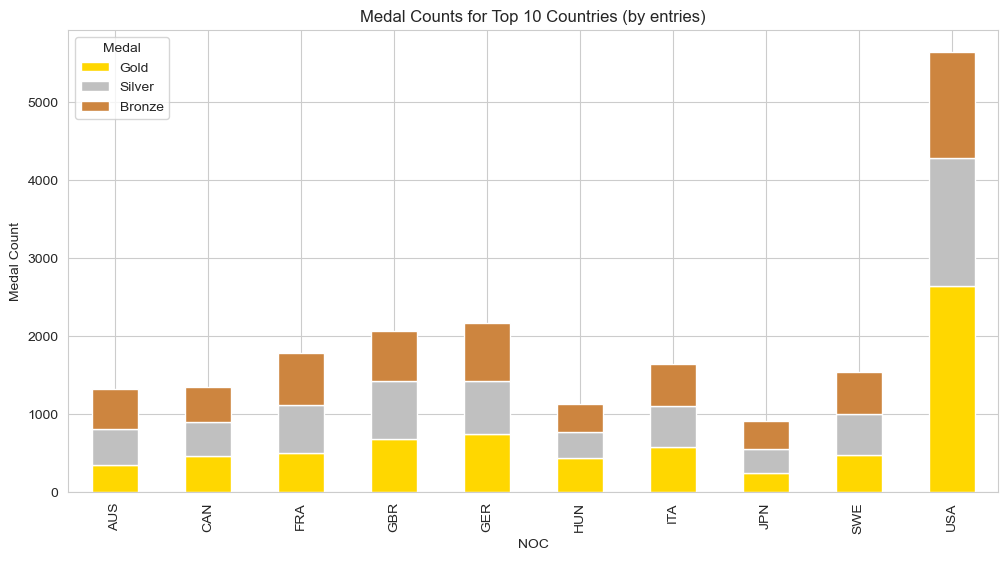

In [28]:
top_countries = df['NOC'].value_counts().head(10).index
medal_by_country = medal_winners[medal_winners['NOC'].isin(top_countries)].groupby(['NOC','Medal']).size().unstack(fill_value=0)
medal_by_country = medal_by_country[['Gold','Silver','Bronze']]
medal_by_country.plot(kind='bar', stacked=True, figsize=(12,6), color=['gold','silver','peru'])
plt.title('Medal Counts for Top 10 Countries (by entries)')
plt.ylabel('Medal Count')
plt.show()


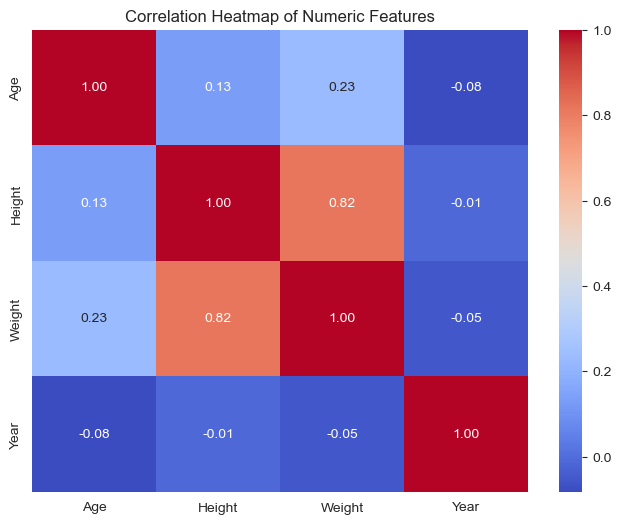

In [29]:
plt.figure(figsize=(8,6))
corr = df[['Age','Height','Weight','Year']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features')
plt.show()


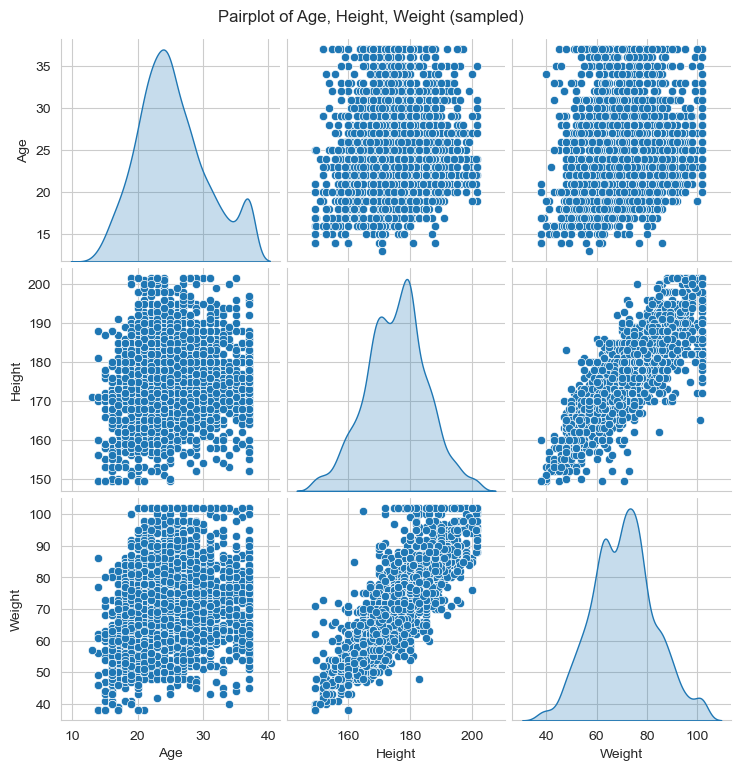

In [39]:
sns.pairplot(df[['Age','Height','Weight']].sample(3000, random_state=42), diag_kind='kde')
plt.suptitle('Pairplot of Age, Height, Weight (sampled)', y=1.02)
plt.show()


## 5. Feature Engineering & Extraction

In [31]:
# 5.1 BMI - derived feature from Height & Weight
df['BMI'] = df['Weight'] / ((df['Height']/100) ** 2)

# 5.2 Is_Medalist - binary flag
df['Is_Medalist'] = np.where(df['Medal'] == 'No Medal', 0, 1)

# 5.3 Age groups (binning)
df['Age_Group'] = pd.cut(df['Age'], bins=[0,18,25,30,35,100],
                          labels=['Teen','Young Adult','Adult','Mid Career','Veteran'])

# 5.4 Extract decade from Year
df['Decade'] = (df['Year'] // 10) * 10

# 5.5 Number of events a country participated in (aggregated feature)
country_event_count = df.groupby('NOC')['Event'].nunique().rename('Country_Event_Diversity')
df = df.merge(country_event_count, on='NOC', how='left')

df[['BMI','Is_Medalist','Age_Group','Decade','Country_Event_Diversity']].head()


,BMI,Is_Medalist,Age_Group,Decade,Country_Event_Diversity
0,24.691358,0,Young Adult,1990,409
1,20.761246,0,Young Adult,2010,409
2,23.040020,0,Young Adult,1920,374
3,28.680111,1,Mid Career,1900,374
4,23.959094,0,Young Adult,1980,398


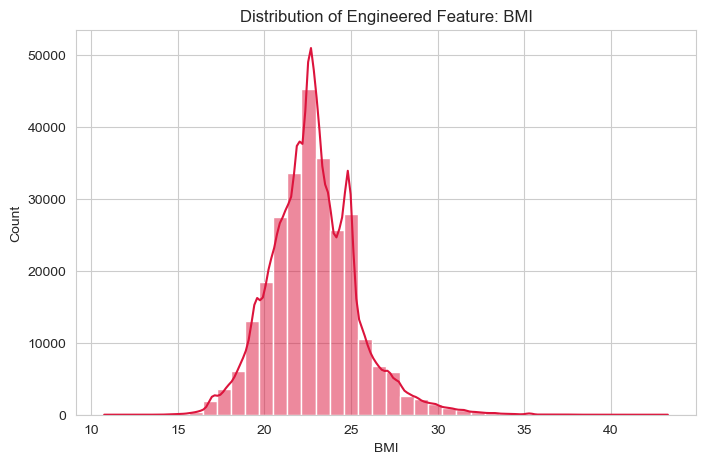

In [32]:
plt.figure(figsize=(8,5))
sns.histplot(df['BMI'], bins=40, kde=True, color='crimson')
plt.title('Distribution of Engineered Feature: BMI')
plt.show()


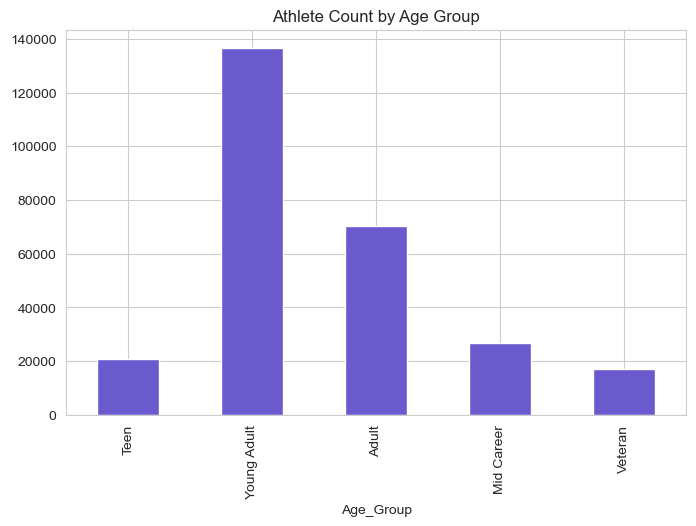

In [33]:
plt.figure(figsize=(8,5))
df['Age_Group'].value_counts().sort_index().plot(kind='bar', color='slateblue')
plt.title('Athlete Count by Age Group')
plt.show()


## 6. Encoding Categorical Variables
The guidelines require converting **all object dtype columns into numeric (int)** form. We use:
- **Label Encoding** for high-cardinality / ordinal-like columns (e.g., `Name`, `Team`, `NOC`, `Games`, `City`, `Sport`, `Event`, `Age_Group`)
- **One-Hot Encoding** for low-cardinality nominal columns (e.g., `Sex`, `Season`, `Medal`)


In [36]:
print('Object dtype columns before encoding:')
print(df.select_dtypes(include='object').columns.tolist())
print('\nCategory dtype columns:')
print(df.select_dtypes(include='category').columns.tolist())


Object dtype columns before encoding:
['Name', 'Sex', 'Team', 'NOC', 'Games', 'Season', 'City', 'Sport', 'Event', 'Medal']

Category dtype columns:
['Age_Group']


### 6.1 Label Encoding (high-cardinality columns)

In [ ]:
label_enc_cols = ['Name', 'Team', 'NOC', 'Games', 'City', 'Sport', 'Event']

le_dict = {}
df_encoded = df.copy()

for col in label_enc_cols:
    le = LabelEncoder()
    df_encoded[col + '_LE'] = le.fit_transform(df_encoded[col].astype(str))
    le_dict[col] = le

df_encoded[[c + '_LE' for c in label_enc_cols]].head()


In [ ]:
# Label encode the ordinal Age_Group too
age_group_order = ['Teen','Young Adult','Adult','Mid Career','Veteran']
age_group_map = {cat: i for i, cat in enumerate(age_group_order)}
df_encoded['Age_Group_LE'] = df_encoded['Age_Group'].map(age_group_map)
df_encoded[['Age_Group','Age_Group_LE']].head()


### 6.2 One-Hot Encoding (low-cardinality nominal columns)

In [ ]:
onehot_cols = ['Sex', 'Season', 'Medal']
df_encoded = pd.get_dummies(df_encoded, columns=onehot_cols, prefix=onehot_cols)

# Convert the resulting boolean one-hot columns to int (0/1)
onehot_result_cols = [c for c in df_encoded.columns if any(c.startswith(p + '_') for p in onehot_cols)]
df_encoded[onehot_result_cols] = df_encoded[onehot_result_cols].astype(int)

df_encoded[onehot_result_cols].head()


In [ ]:
# Drop original object/category columns now that encoded versions exist
cols_to_drop = label_enc_cols + ['Age_Group']
df_encoded = df_encoded.drop(columns=cols_to_drop)

print('Remaining dtypes:')
print(df_encoded.dtypes.value_counts())


In [ ]:
# Final check - confirm NO object dtype columns remain
remaining_object_cols = df_encoded.select_dtypes(include='object').columns.tolist()
print('Remaining object columns:', remaining_object_cols)
df_encoded.head()


## 7. Feature Scaling
We scale the continuous numeric features using **StandardScaler** (z-score normalization), which is appropriate for most downstream ML algorithms.

In [ ]:
numeric_cols_to_scale = ['Age', 'Height', 'Weight', 'BMI', 'Year', 'Decade', 'Country_Event_Diversity']

scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_scaled[numeric_cols_to_scale])

df_scaled[numeric_cols_to_scale].describe().T


In [ ]:
# Alternative: Min-Max Scaling (0-1 range) demonstrated for comparison
minmax_scaler = MinMaxScaler()
df_minmax_demo = df_encoded.copy()
df_minmax_demo[numeric_cols_to_scale] = minmax_scaler.fit_transform(df_minmax_demo[numeric_cols_to_scale])
df_minmax_demo[numeric_cols_to_scale].describe().T


In [ ]:
print('Final shape of fully processed, encoded, and scaled dataset:', df_scaled.shape)
print('\nAll columns and dtypes:')
df_scaled.dtypes


In [ ]:
# Save the final processed dataset
df_scaled.to_csv('athlete_data_processed.csv', index=False)
print('Processed dataset saved as athlete_data_processed.csv')


## 8. Insights and Interpretation

**Key Findings:**

1. **Gender Participation Gap:** Male athletes vastly outnumber female athletes overall (~196,594 vs ~74,522 entries), although the gap has narrowed significantly since the 1990s, reflecting growing gender parity in the Olympics.

2. **Summer vs Winter:** The Summer Olympics dominate the dataset (~222,552 entries vs ~48,564 for Winter), consistent with more sports/events being held in the Summer Games.

3. **Missing Data Pattern:** Height and Weight were missing for a substantial portion of early-20th-century records, suggesting these measurements were not consistently recorded until more recent decades — imputing by Sex+Sport group preserved realistic physiological differences across disciplines (e.g., gymnasts vs. weightlifters).

4. **Medal Distribution:** Only a small fraction of athlete-entries (about 13,000 each for Gold/Silver/Bronze out of ~271,000 total entries) result in a medal — most participants do not medal, as expected given Olympic competition structure.

5. **Body Metrics by Sport:** Height and Weight show strong sport-specific clustering (e.g., basketball/rowing athletes are taller and heavier; gymnastics athletes are shorter and lighter), visible in the BMI distribution and scatterplots.

6. **Dominant Nations:** A small group of countries (USA, Soviet Union/Russia, Germany, UK, France, etc.) account for a disproportionately large share of both participation and medals, reflecting historical investment in Olympic sport programs.

7. **Age Trends:** Most athletes compete in their early-to-mid twenties; medal-winning age distributions are similar across Gold/Silver/Bronze, suggesting competitive performance peaks are consistent regardless of medal outcome.

8. **Growth Over Time:** The number of unique athletes per Olympic Games has grown substantially since 1896, with notable dips around the World War years (1916, 1940, 1944), reflecting historical disruptions.

**Conclusion:** This EDA reveals clear demographic, physiological, and historical patterns in Olympic participation. The cleaned, encoded, and scaled dataset (`athlete_data_processed.csv`) is now ready for downstream machine learning tasks such as predicting medal likelihood (`Is_Medalist`) based on physical attributes, country, sport, and event features.
